In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv("Mall_Customers.csv")

print("Dataset Head:")
print(df.head())

Dataset Head:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   49                  68                      69
1           2  Female   56                  22                      47
2           3    Male   66                  41                      94
3           4    Male   69                  41                      62
4           5    Male   49                 112                      69


In [ ]:
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [ ]:
print("\nFirst 10 Rows:")
print(df.head(10))


First 10 Rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   49                  68                      69
1           2  Female   56                  22                      47
2           3    Male   66                  41                      94
3           4    Male   69                  41                      62
4           5    Male   49                 112                      69
5           6  Female   21                  35                      76
6           7    Male   47                  44                      16
7           8    Male   54                 111                      90
8           9    Male   40                  42                      90
9          10  Female   56                 125                      48


In [ ]:
https://chatgpt.com/share/6ab366a7-376c-83e8-b188-548dbf30ca3b

SyntaxError: invalid decimal literal (831791655.py, line 1)

In [ ]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

print(X[:10])

[[ 68  69]
 [ 22  47]
 [ 41  94]
 [ 41  62]
 [112  69]
 [ 35  76]
 [ 44  16]
 [111  90]
 [ 42  90]
 [125  48]]


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:10])

[[-0.21615354  0.6640981 ]
 [-1.51845383 -0.08822725]
 [-0.98054719  1.51901327]
 [-0.98054719  0.42472186]
 [ 1.029525    0.6640981 ]
 [-1.15041244  0.90347435]
 [-0.89561456 -1.14832206]
 [ 1.00121413  1.38222685]
 [-0.95223631  1.38222685]
 [ 1.39756639 -0.05403064]]


In [ ]:
wcss = []
silhouette_scores = []

K_range = range(2, 11)

In [ ]:
for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_scaled, kmeans.labels_)
    )

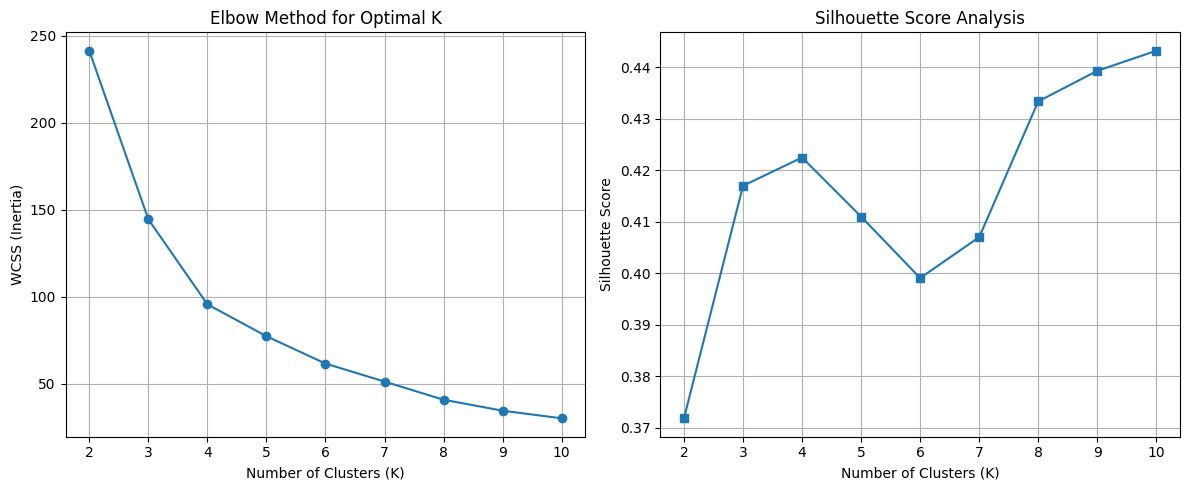

In [ ]:
plt.figure(figsize=(12, 5))

# Elbow Method
plt.subplot(1, 2, 1)

plt.plot(
    range(2, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.grid(True)


# Silhouette Score
plt.subplot(1, 2, 2)

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='s'
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = y_kmeans

print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   49                  68                      69   
1           2  Female   56                  22                      47   
2           3    Male   66                  41                      94   
3           4    Male   69                  41                      62   
4           5    Male   49                 112                      69   

   Cluster  
0        1  
1        2  
2        1  
3        1  
4        3  


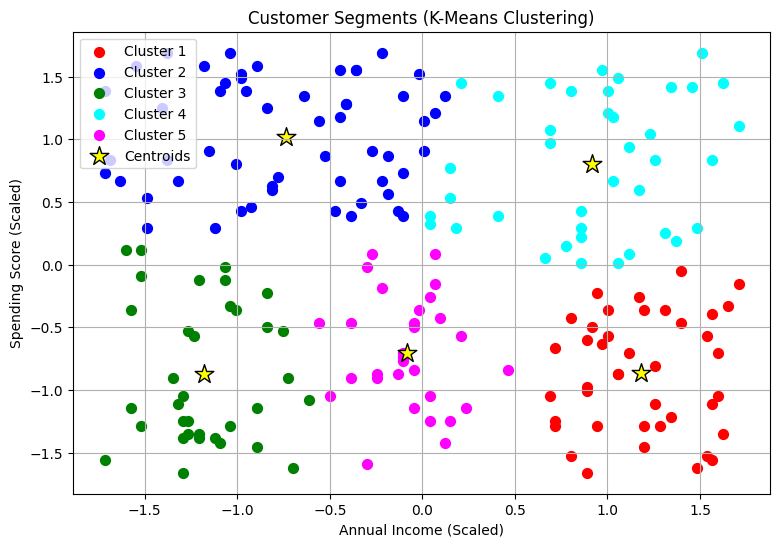

In [ ]:
plt.figure(figsize=(9, 6))

colors = ['red', 'blue', 'green', 'cyan', 'magenta']

labels = [
    'Cluster 1',
    'Cluster 2',
    'Cluster 3',
    'Cluster 4',
    'Cluster 5'
]

for i in range(optimal_k):

    plt.scatter(
        X_scaled[y_kmeans == i, 0],
        X_scaled[y_kmeans == i, 1],
        s=50,
        c=colors[i],
        label=labels[i]
    )

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='yellow',
    edgecolors='black',
    marker='*',
    label='Centroids'
)

plt.title("Customer Segments (K-Means Clustering)")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
profile = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)', 'Age']
].mean()

print(profile)

         Annual Income (k$)  Spending Score (1-100)        Age
Cluster                                                       
0                117.390244               24.243902  41.682927
1                 49.636364               79.363636  44.327273
2                 34.057143               24.057143  43.942857
3                108.000000               72.923077  47.769231
4                 72.666667               29.033333  44.433333


In [ ]:
print("Number of customers in each cluster:")

print(df['Cluster'].value_counts().sort_index())

Number of customers in each cluster:
Cluster
0    41
1    55
2    35
3    39
4    30
Name: count, dtype: int64
